# Fully Connected Network for MNIST / Mạng nơ-ron kết nối đầy đủ

Tôi thực hành `784 → 128 → 64 → 10`, trực quan hóa, train/validation/test và lưu/tải mô hình.
**Input:** ảnh 28×28. **Output:** xác suất chữ số, accuracy, confusion matrix và tệp `.keras`.

Coursework practice from `Bài tập về nhà buổi 7 - Lập trình python.ipynb`.
Full official dataset: **54,000 train / 6,000 validation / 10,000 test**; seed 42;
10 epochs, batch 128 for CPU execution. Follow the [run guide](../README.md).

## Chuẩn bị dữ liệu / Prepare data

Chỉ tách validation từ bộ train chính thức. Ảnh được đổi sang float32 rồi chia 255.
The official test split is reserved for final evaluation; normalization has no fitted parameters.
Data loader: [Keras MNIST](https://keras.io/api/datasets/mnist/).

In [1]:
import os
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

SEED = 42
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
# Hai luồng CPU, phù hợp máy nhỏ / Bound CPU threads for small machines.
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
print('TensorFlow:', tf.__version__, '| Keras:', tf.keras.__version__)

TensorFlow: 2.21.0 | Keras: 3.15.1


In [2]:
from pathlib import Path
import hashlib

mnist = tf.keras.datasets.mnist
(x_all, y_all), (x_test, y_test) = mnist.load_data()
mnist_path = Path(os.environ.get('KERAS_HOME', str(Path.home() / '.keras'))) / 'datasets/mnist.npz'
mnist_sha256 = hashlib.sha256(mnist_path.read_bytes()).hexdigest()
assert mnist_sha256 == '731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1'
assert x_all.shape == (60000, 28, 28) and x_test.shape == (10000, 28, 28)
x_all = x_all.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
x_train, x_valid, y_train, y_valid = train_test_split(
    x_all, y_all, test_size=0.1, stratify=y_all, random_state=SEED
)
del x_all, y_all
BATCH_SIZE = 128
options = tf.data.Options()
options.threading.private_threadpool_size = 2
options.threading.max_intra_op_parallelism = 1

def batches(x, y, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        dataset = dataset.shuffle(len(y), seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(BATCH_SIZE).with_options(options).prefetch(1)

train_ds = batches(x_train, y_train, training=True)
valid_ds = batches(x_valid, y_valid)
test_ds = batches(x_test, y_test)
print('Train/validation/test:', len(y_train), len(y_valid), len(y_test))
print('MNIST SHA-256:', mnist_sha256)

Train/validation/test: 54000 6000 10000
MNIST SHA-256: 731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1


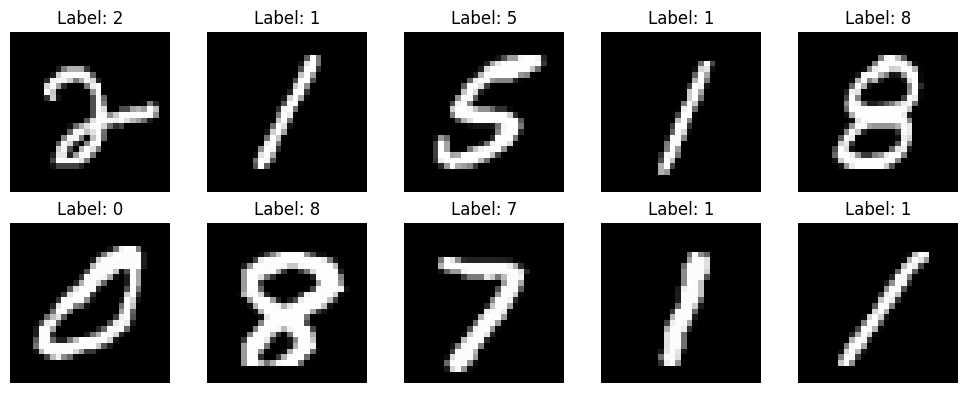

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap='gray')
    ax.set_title(f'Label: {y_train[i]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [4]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax'),
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘


 Total params: 109,386 (427.29 KB)


 Trainable params: 109,386 (427.29 KB)


 Non-trainable params: 0 (0.00 B)


Epoch 1/10


422/422 - 2s - 4ms/step - accuracy: 0.9035 - loss: 0.3456 - val_accuracy: 0.9427 - val_loss: 0.1994


Epoch 2/10


422/422 - 1s - 2ms/step - accuracy: 0.9565 - loss: 0.1453 - val_accuracy: 0.9545 - val_loss: 0.1553


Epoch 3/10


...

422/422 - 1s - 2ms/step - accuracy: 0.9885 - loss: 0.0360 - val_accuracy: 0.9728 - val_loss: 0.1035


Epoch 9/10


422/422 - 1s - 2ms/step - accuracy: 0.9910 - loss: 0.0289 - val_accuracy: 0.9757 - val_loss: 0.0899


Epoch 10/10


422/422 - 1s - 2ms/step - accuracy: 0.9936 - loss: 0.0223 - val_accuracy: 0.9765 - val_loss: 0.0891


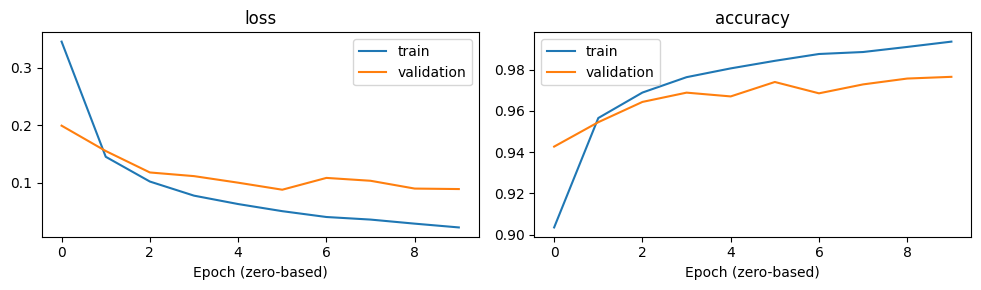

In [5]:
history = model.fit(train_ds, validation_data=valid_ds, epochs=10, shuffle=False, verbose=2)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, metric in zip(axes, ['loss', 'accuracy']):
    ax.plot(history.history[metric], label='train')
    ax.plot(history.history['val_' + metric], label='validation')
    ax.set_xlabel('Epoch (zero-based)')
    ax.set_title(metric)
    ax.legend()
plt.tight_layout()
plt.show()

In [6]:
from sklearn.metrics import classification_report, confusion_matrix

test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)
predictions = model.predict(test_ds, verbose=0)
assert predictions.shape == (10000, 10) and np.isfinite(predictions).all()
assert (predictions >= 0).all() and np.isfinite(test_loss)
assert 0 <= test_accuracy <= 1
np.testing.assert_allclose(predictions.sum(axis=1), 1.0, atol=1e-6)
predicted_digits = predictions.argmax(axis=1)
assert np.isclose(test_accuracy, (predicted_digits == y_test).mean(), atol=1e-6)
print(f'Test accuracy: {test_accuracy:.4f} | Test loss: {test_loss:.4f}')
print(classification_report(y_test, predicted_digits, digits=4, zero_division=0))
print('Confusion matrix (rows=true, columns=predicted):')
print(confusion_matrix(y_test, predicted_digits))

Test accuracy: 0.9772 | Test loss: 0.0807
              precision    recall  f1-score   support

           0     0.9769    0.9939    0.9853       980
           1     0.9921    0.9912    0.9916      1135
           2     0.9777    0.9777    0.9777      1032
           3     0.9558    0.9851    0.9703      1010
           4     0.9699    0.9837    0.9767       982
           5     0.9786    0.9731    0.9758       892
           6     0.9852    0.9708    0.9779       958
           7     0.9748    0.9786    0.9767      1028
           8     0.9831    0.9538    0.9682       974
           9     0.9778    0.9613    0.9695      1009

    accuracy                         0.9772     10000
   macro avg     0.9772    0.9769    0.9770     10000
weighted avg     0.9773    0.9772    0.9772     10000

Confusion matrix (rows=true, columns=predicted):
[[ 974    0    1    0    0    1    1    1    2    0]
 [   0 1125    4    0    0    0    2    1    3    0]
 [   3    0 1009    5    3    0    2    6   

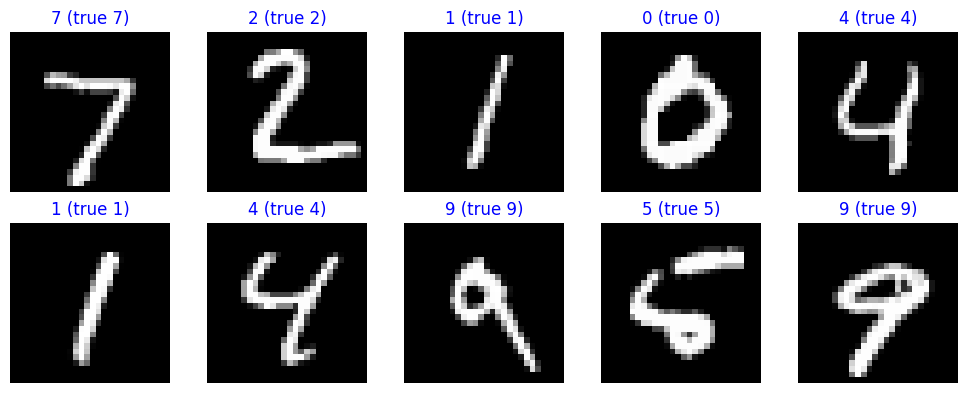

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i], cmap='gray')
    predicted, actual = int(predicted_digits[i]), int(y_test[i])
    ax.set_title(f'{predicted} (true {actual})', color='blue' if predicted == actual else 'red')
    ax.axis('off')
plt.tight_layout()
plt.show()

## Lưu và kiểm tra tải lại / Save and reload

Dùng định dạng `.keras`, rồi đối chiếu toàn bộ xác suất test trước và sau tải lại.
The saved file contains model structure and weights; reload should preserve predictions.

In [8]:
cwd = Path.cwd()
labs_dir = cwd.parent if cwd.name == 'notebooks' else (cwd if cwd.name == 'labs' else cwd / 'labs')
artifact_dir = labs_dir / 'artifacts'
artifact_dir.mkdir(parents=True, exist_ok=True)
model_path = artifact_dir / 'mnist_fcn_model.keras'
model.save(model_path)
reloaded_model = tf.keras.models.load_model(model_path)
reloaded_predictions = reloaded_model.predict(test_ds, verbose=0)
np.testing.assert_allclose(reloaded_predictions, predictions, atol=1e-7, rtol=1e-6)
reload_max_abs_diff = float(np.max(np.abs(reloaded_predictions - predictions)))
LAB_RESULT = {
    'test_loss': float(test_loss), 'test_accuracy': float(test_accuracy),
    'train_rows': len(y_train), 'validation_rows': len(y_valid), 'test_rows': len(y_test),
    'epochs': len(history.history['loss']), 'batch_size': BATCH_SIZE,
    'last_validation_accuracy': float(history.history['val_accuracy'][-1]),
    'reload_max_abs_diff': reload_max_abs_diff, 'data_sha256': mnist_sha256,
}
print('Model saved to:', model_path.name)
print(LAB_RESULT)

Model saved to: mnist_fcn_model.keras
{'test_loss': 0.08073531091213226, 'test_accuracy': 0.9771999716758728, 'train_rows': 54000, 'validation_rows': 6000, 'test_rows': 10000, 'epochs': 10, 'batch_size': 128, 'last_validation_accuracy': 0.9764999747276306, 'reload_max_abs_diff': 0.0, 'data_sha256': '731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1'}


## Điều tôi rút ra / What I learned

Tôi phân biệt ba tập dữ liệu, theo dõi train/validation và kiểm tra cả hành vi lưu/tải.
Loss test có thể tăng trong khi accuracy vẫn tốt nếu mô hình tự tin ở các mẫu sai.
Kiến trúc và số epoch trong bài được chọn trước; tôi chưa dò tham số theo test.

Separate data splits and a reload check make the training exercise reproducible.
Accuracy and cross-entropy describe different aspects of errors. Results may vary slightly
across TensorFlow versions or hardware despite the fixed seed.